<a href="https://colab.research.google.com/github/erickcorrea3092/Cheminformatics-course/blob/main/4_3_rdkit_descriptors_group_excel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

In [ ]:
!pip install --upgrade gdown

In [ ]:
! pip install rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
import pandas as pd
#from Descriptors import descListToDict

In [ ]:
#vamos a usar un función que nos ayudará a calcular los descriptores
def get_descriptors(mol):
    descriptor_dict = {}
    for descriptor_name, descriptor_function in Descriptors.descList:
        descriptor_value = descriptor_function(mol)
        descriptor_dict[descriptor_name] = descriptor_value
    return descriptor_dict

#Datos

In [ ]:
! gdown --id 1HTcn2Dy3YG12bghKB9d5FHmR0G8DX79l #Invoca al archivo desde Drive
df = pd.read_excel("s_au.xlsx")#en formato excel
#df = pd.read_csv("s_au.csv")#en formato.csv

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1HTcn2Dy3YG12bghKB9d5FHmR0G8DX79l
To: /content/s_au.xlsx
100% 9.71k/9.71k [00:00<00:00, 20.7MB/s]


In [ ]:
df.head(6)

,Smiles,pMIC
0,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...,5.005513
1,O=C1NC2=CC=CC=C2/C1=N\C3SC(C=CC(OCC)=C4)=C4N3,4.114064
2,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...,5.047677
3,O=C1CSC(C2=CC=C([N+]([O-])=O)C=C2)N1C3=NC4=C(C...,3.813648
4,O=C1CSC(C2=CC=C(OC)C=C2)N1C3=NC4=CC=C(OCC)C=C4S3,4.109556
5,OC1=C(C(NC2=NC(C(C)=CC=C3)=C3S2)C4=CC=C(O)C=C4...,3.916054


También podemos invocar al archivo desde un disco local

In [ ]:
from google.colab import files
# uploaded = files.upload()

In [ ]:
dataframe = pd.read_excel('s_au.xlsx')
#dataframe = pd.read_csv('s_au.csv')

In [ ]:
from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataframe,'Smiles', 'Structure')


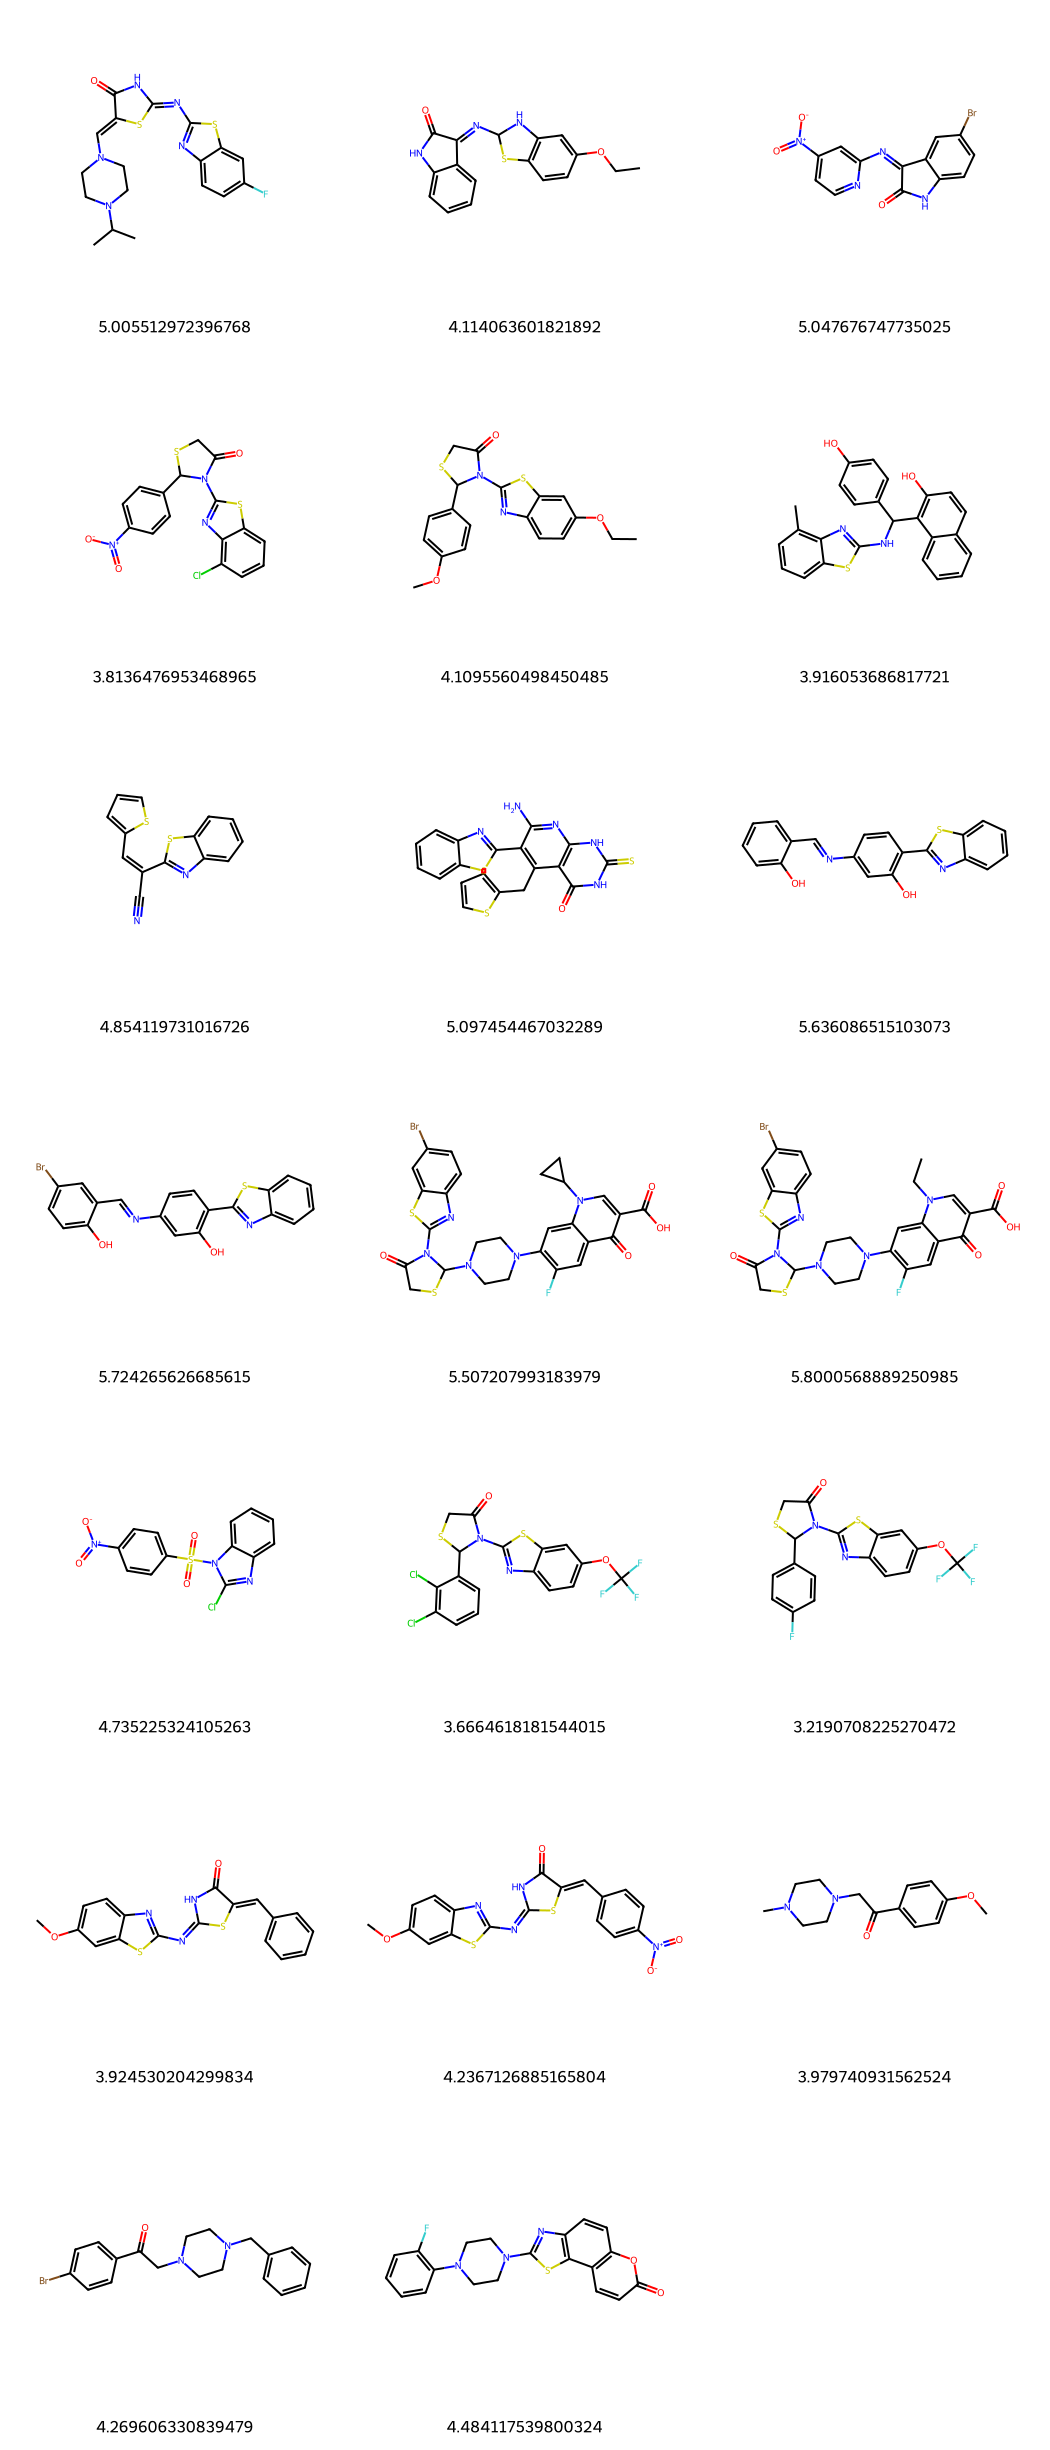

In [ ]:
from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in dataframe["Structure"]][:20], maxMols=100,
                     legends=[str(x) for x in dataframe.pMIC], subImgSize=(350,350), molsPerRow=3)

In [ ]:
compuestos = dataframe['Smiles']
descriptors = []
for compuesto in compuestos:
    mol = Chem.MolFromSmiles(compuesto)
    descriptor_dict = get_descriptors(mol)
    descriptors.append(descriptor_dict)

In [ ]:
df

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,13.311012,13.311012,0.141486,-0.294740,0.795224,21.777778,405.524,385.364,405.109330,142,...,1,0,0,0,0,1,0,0,0,0
1,12.132241,12.132241,0.153184,-0.214090,0.908493,19.956522,325.393,310.273,325.088498,116,...,1,0,0,0,0,0,0,0,0,0
2,11.946832,11.946832,0.113125,-0.537083,0.667152,14.904762,347.128,340.072,345.970152,104,...,0,0,0,0,0,0,0,0,0,0
3,12.425907,12.425907,0.024437,-0.440440,0.479949,17.400000,391.861,381.781,390.985211,126,...,1,0,0,0,0,1,0,0,0,0
4,12.550188,12.550188,0.069138,-0.069138,0.646964,17.076923,386.498,368.354,386.075884,134,...,1,0,0,0,0,1,0,0,0,0
5,10.850403,10.850403,0.203938,-0.335585,0.320810,12.300000,412.514,392.354,412.124549,148,...,0,0,0,0,0,1,0,0,0,0
6,9.256438,9.256438,0.623750,0.623750,0.644913,11.611111,268.366,260.302,268.012890,86,...,0,0,0,0,0,1,0,1,0,0
7,12.779193,12.779193,0.221491,-0.277623,0.371250,11.428571,423.548,410.444,423.028223,138,...,0,0,0,0,0,1,0,1,0,0
8,10.365119,10.365119,0.130546,0.130546,0.505719,11.360000,346.411,332.299,346.077599,122,...,0,0,0,0,0,1,0,0,0,0
9,10.401734,10.401734,0.122380,0.122380,0.402637,11.423077,425.307,412.203,423.988111,128,...,0,0,0,0,0,1,0,0,0,0


In [ ]:
df = pd.DataFrame(descriptors)
#df.to_csv('descriptores.csv', index=False)
df.to_excel('descriptores_salida.xlsx', index=False)

In [ ]:
df_y = dataframe["pMIC"]
SMILES = dataframe["Smiles"]
df_data = df.assign(pMIC=df_y)
df_data = df_data.assign(SMILES=SMILES)
df_data
#df.to_csv('descriptores_n_activity.csv', index=False)
df.to_excel('descriptores_n_activity.xlsx', index=False)

In [ ]:
df_data

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,pMIC,SMILES
0,13.311012,13.311012,0.141486,-0.294740,0.795224,21.777778,405.524,385.364,405.109330,142,...,0,0,0,1,0,0,0,0,5.005513,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...
1,12.132241,12.132241,0.153184,-0.214090,0.908493,19.956522,325.393,310.273,325.088498,116,...,0,0,0,0,0,0,0,0,4.114064,O=C1NC2=CC=CC=C2/C1=N\C3SC(C=CC(OCC)=C4)=C4N3
2,11.946832,11.946832,0.113125,-0.537083,0.667152,14.904762,347.128,340.072,345.970152,104,...,0,0,0,0,0,0,0,0,5.047677,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...
3,12.425907,12.425907,0.024437,-0.440440,0.479949,17.400000,391.861,381.781,390.985211,126,...,0,0,0,1,0,0,0,0,3.813648,O=C1CSC(C2=CC=C([N+]([O-])=O)C=C2)N1C3=NC4=C(C...
4,12.550188,12.550188,0.069138,-0.069138,0.646964,17.076923,386.498,368.354,386.075884,134,...,0,0,0,1,0,0,0,0,4.109556,O=C1CSC(C2=CC=C(OC)C=C2)N1C3=NC4=CC=C(OCC)C=C4S3
5,10.850403,10.850403,0.203938,-0.335585,0.320810,12.300000,412.514,392.354,412.124549,148,...,0,0,0,1,0,0,0,0,3.916054,OC1=C(C(NC2=NC(C(C)=CC=C3)=C3S2)C4=CC=C(O)C=C4...
6,9.256438,9.256438,0.623750,0.623750,0.644913,11.611111,268.366,260.302,268.012890,86,...,0,0,0,1,0,1,0,0,4.854120,N#C/C(C1=NC2=CC=CC=C2S1)=C/C3=CC=CS3
7,12.779193,12.779193,0.221491,-0.277623,0.371250,11.428571,423.548,410.444,423.028223,138,...,0,0,0,1,0,1,0,0,5.097454,O=C(C1=C(N2)N=C(N)C(C3=NC4=CC=CC=C4S3)=C1CC5=C...
8,10.365119,10.365119,0.130546,0.130546,0.505719,11.360000,346.411,332.299,346.077599,122,...,0,0,0,1,0,0,0,0,5.636087,OC(C=CC=C1)=C1/C=N/C(C=C2O)=CC=C2C3=NC4=CC=CC=...
9,10.401734,10.401734,0.122380,0.122380,0.402637,11.423077,425.307,412.203,423.988111,128,...,0,0,0,1,0,0,0,0,5.724266,OC(C=CC(Br)=C1)=C1/C=N/C(C=C2O)=CC=C2C3=NC4=CC...


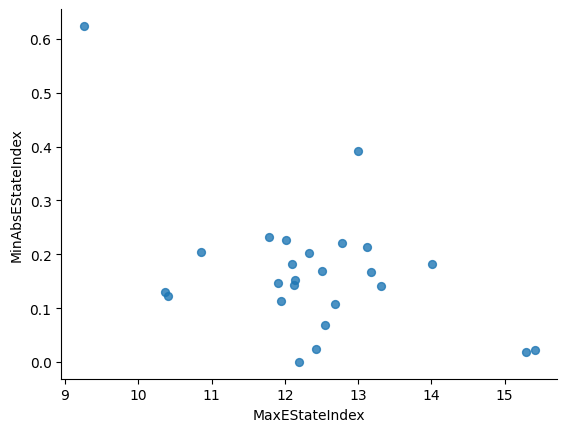

In [ ]:
from matplotlib import pyplot as plt
df_data.plot(kind='scatter', x='MaxEStateIndex', y='MinAbsEStateIndex', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
from google.colab import files
#files.download('descriptores.csv')
#files.download('descriptores_n_activity.csv')
#files.download('descriptores.xlsx')
files.download('descriptores_n_activity.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>